# Substructure Analysis — Caspase & Mito Datasets
Identifies shared structural features in compounds active in **both** caspase and mito assays.

**Pipeline (active compounds only — inactives excluded throughout):**
1. Load 3 activity groups: Both-Active, Caspase-Only, Mito-Only
2. BRICS fragment frequency (both-active compounds)
3. t-SNE chemical space (all active groups)
4. Fragment enrichment — Fisher's exact test (both-active vs single-active)
5. Composite toxicity score & highlighted structures

In [17]:
# ── Imports ──────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import warnings
import re
from collections import Counter

import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from sklearn.manifold import TSNE

from rdkit import Chem, DataStructs
from rdkit.Chem import BRICS, AllChem, Draw

warnings.filterwarnings("ignore")

In [18]:
# ── Load 3 activity groups (inactives excluded) ─────────────────────────────
# We only keep compounds with at least one assay activity signal.
BASE = "/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_mito_comparisons"
SMILES_COL = "PUBCHEM_EXT_DATASOURCE_SMILES"
COLS = ["PUBCHEM_CID", SMILES_COL]

both_df = pd.read_csv(f"{BASE}/caspase_and_mito_Active.csv",         low_memory=False)[COLS].dropna()
casp_df = pd.read_csv(f"{BASE}/caspase_active_and_mito_inctive.csv",  low_memory=False)[COLS].dropna()
mito_df = pd.read_csv(f"{BASE}/caspase_inactive_and_mito_active.csv", low_memory=False)[COLS].dropna()

both_df["group"] = "Both Active"
casp_df["group"] = "Caspase Only"
mito_df["group"] = "Mito Only"

print(f"Both-active : {len(both_df)}")
print(f"Caspase-only: {len(casp_df)}")
print(f"Mito-only   : {len(mito_df)}")
print(f"Total active: {len(both_df) + len(casp_df) + len(mito_df)}")

Both-active : 288
Caspase-only: 34
Mito-only   : 1944
Total active: 2266


In [19]:
# ── BRICS Fragment Analysis (Both-Active compounds) ───────────────────────────
# BRICS breaks molecules at predefined retrosynthetic bonds.
# We collect every fragment from every both-active compound and count them.

all_fragments = []
for smi in both_df[SMILES_COL]:
    mol = Chem.MolFromSmiles(smi)
    if mol:
        all_fragments.extend(BRICS.BRICSDecompose(mol))

fragment_counts = Counter(all_fragments)
print(f"Total fragment occurrences : {len(all_fragments)}")
print(f"Unique fragments           : {len(fragment_counts)}")

# Show top 15 most common fragments
print("Top 15 fragments:")
for frag, cnt in fragment_counts.most_common(15):
    print(f"  {cnt:4d}  {frag}")

Total fragment occurrences : 862
Unique fragments           : 235
Top 15 fragments:
    44  [3*]O[3*]
    32  [3*]OC
    26  [5*]N[5*]
    26  [16*]c1ccccc1
    24  [16*]c1ccc(O)cc1
    20  [1*]C([6*])=O
    18  [16*]c1ccc([16*])cc1
    14  [8*]C[8*]
    14  [8*]C(C)(C)C
    14  [4*]C[8*]
    10  [8*]C(F)(F)F
    10  [16*]c1ccc(O)c([16*])c1
    10  [4*]CC
    10  [5*]N(C)C
    10  [5*]N([5*])[5*]


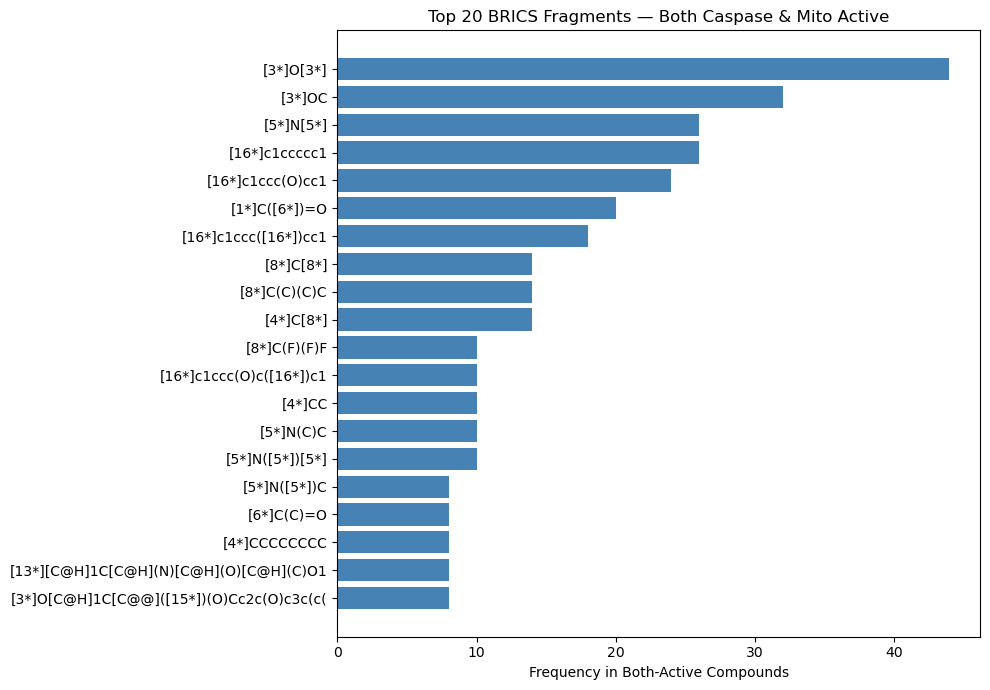

In [20]:
# ── Bar chart: top 20 BRICS fragments ────────────────────────────────────────
top20 = fragment_counts.most_common(20)
labels = [f[0][:40] for f in top20]   # truncate long SMILES strings for readability
counts = [f[1]      for f in top20]

plt.figure(figsize=(10, 7))
plt.barh(labels[::-1], counts[::-1], color="steelblue")
plt.xlabel("Frequency in Both-Active Compounds")
plt.title("Top 20 BRICS Fragments — Both Caspase & Mito Active")
plt.tight_layout()
plt.show()

In [21]:
# ── t-SNE Chemical Space (active compounds only) ─────────────────────────────
# Morgan fingerprints (ECFP4, 2048 bits) encode the circular neighbourhood
# of each atom. t-SNE compresses them to 2-D for visualization.

# Combine all 3 active groups
combined = pd.concat([both_df, casp_df, mito_df], ignore_index=True)

# Compute one fingerprint per compound
def smiles_to_fp(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol:
        return AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
    return None

combined["fp"] = combined[SMILES_COL].apply(smiles_to_fp)
valid = combined[combined["fp"].notna()].copy().reset_index(drop=True)
fp_matrix = np.array([list(fp) for fp in valid["fp"]])

# Run t-SNE (perplexity=30 is a good default for hundreds of compounds)
print(f"Running t-SNE on {len(valid)} active compounds...")
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
coords = tsne.fit_transform(fp_matrix)
valid["tsne_x"], valid["tsne_y"] = coords[:, 0], coords[:, 1]
print("Done.")

[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerator
[19:03:46] DEPRECATION WARNING: please use MorganGenerat

Running t-SNE on 2266 active compounds...
Done.


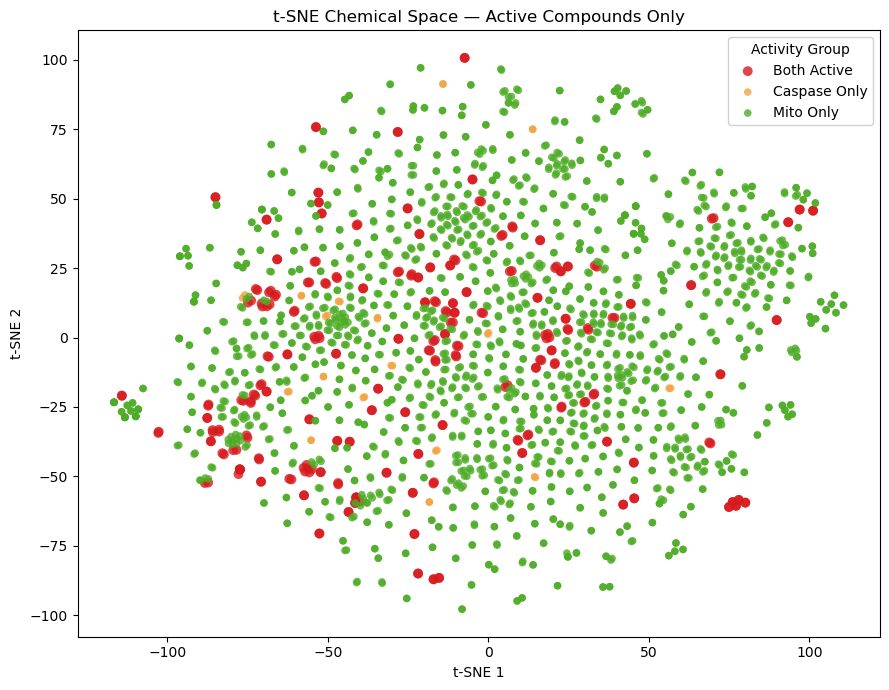

In [22]:
# ── t-SNE Plot: colour by activity group ─────────────────────────────────────
COLOR_MAP = {
    "Mito Only":    "#4dac26",
    "Caspase Only": "#f1a340",
    "Both Active":  "#d7191c",
}
SIZE_MAP = {"Mito Only": 30, "Caspase Only": 30, "Both Active": 50}

plt.figure(figsize=(9, 7))
for group, gdf in valid.groupby("group"):
    plt.scatter(gdf["tsne_x"], gdf["tsne_y"],
                c=COLOR_MAP[group], s=SIZE_MAP[group],
                label=group, alpha=0.8, edgecolors="none")

plt.legend(title="Activity Group", framealpha=0.9)
plt.title("t-SNE Chemical Space — Active Compounds Only")
plt.xlabel("t-SNE 1");  plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

---
## KMeans Clustering
Groups active compounds into **5 clusters** based on Morgan fingerprint similarity.
- Each cluster = a chemically similar family of compounds
- The t-SNE shows where each cluster sits in chemical space
- The composition table reveals which clusters are enriched in dual-active compounds
- Representative structures show the most central molecule from each cluster

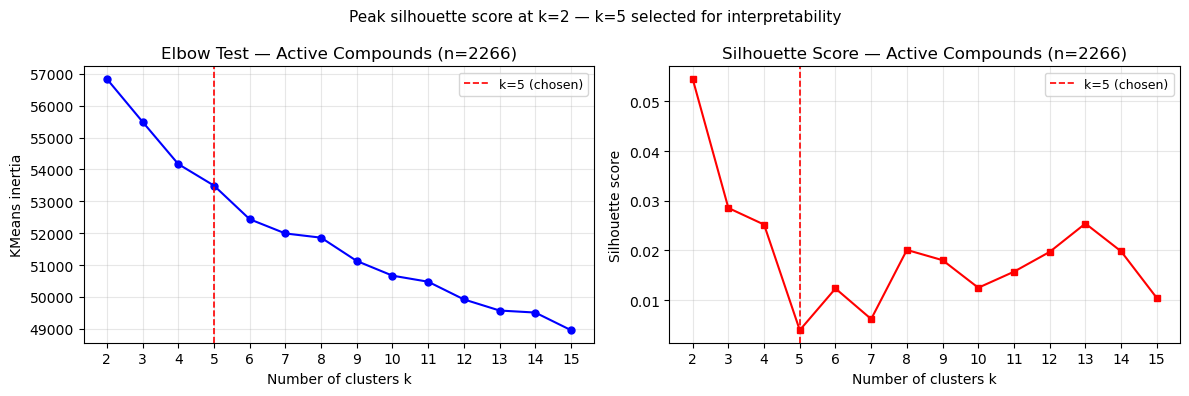

Silhouette scores: {2: 0.0545, 3: 0.0285, 4: 0.0252, 5: 0.004, 6: 0.0123, 7: 0.0062, 8: 0.0201, 9: 0.018, 10: 0.0125, 11: 0.0157, 12: 0.0197, 13: 0.0254, 14: 0.0198, 15: 0.0104}
Peak silhouette at k=2 (score=0.0545)


In [23]:
# ── Elbow test: justify k=5 for KMeans on 2,266 active compounds ─────────────
# We sweep k from 2 to 15 and record:
#   inertia       — sum of squared distances to centroid (lower = tighter clusters)
#   silhouette    — mean inter/intra cluster separation (-1..1, higher = better)
# The 'elbow' where inertia stops falling fast, combined with the silhouette
# peak, identifies the optimal k.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(2, 16)
inertias, silhouettes = [], []

for k in K_RANGE:
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_tmp.fit_predict(fp_matrix)
    inertias.append(km_tmp.inertia_)
    silhouettes.append(silhouette_score(fp_matrix, labels, sample_size=1000, random_state=42))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(list(K_RANGE), inertias, 'bo-', linewidth=1.5, markersize=5)
ax1.axvline(5, color='red', linestyle='--', linewidth=1.2, label='k=5 (chosen)')
ax1.set_xlabel('Number of clusters k')
ax1.set_ylabel('KMeans inertia')
ax1.set_title('Elbow Test — Active Compounds (n=2266)')
ax1.set_xticks(list(K_RANGE))
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2.plot(list(K_RANGE), silhouettes, 'rs-', linewidth=1.5, markersize=5)
ax2.axvline(5, color='red', linestyle='--', linewidth=1.2, label='k=5 (chosen)')
ax2.set_xlabel('Number of clusters k')
ax2.set_ylabel('Silhouette score')
ax2.set_title('Silhouette Score — Active Compounds (n=2266)')
ax2.set_xticks(list(K_RANGE))
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

best_k = list(K_RANGE)[silhouettes.index(max(silhouettes))]
plt.suptitle(f'Peak silhouette score at k={best_k} — k=5 selected for interpretability',
             fontsize=11)
plt.tight_layout()
plt.show()
print(f'Silhouette scores: {dict(zip(K_RANGE, [round(s,4) for s in silhouettes]))}')
print(f'Peak silhouette at k={best_k} (score={max(silhouettes):.4f})')

In [24]:
# ── KMeans clustering on Morgan fingerprints ──────────────────────────────────
# fp_matrix and valid are already computed in the t-SNE cell above.
# We use MiniBatchKMeans for speed; n_clusters=5 gives interpretable groups.
from sklearn.cluster import MiniBatchKMeans

N_CLUSTERS = 5
km = MiniBatchKMeans(n_clusters=N_CLUSTERS, random_state=42, n_init='auto')
valid['cluster'] = km.fit_predict(fp_matrix)

print('Compounds per cluster:')
print(valid['cluster'].value_counts().sort_index().to_string())

Compounds per cluster:
cluster
0     272
1      24
2      76
3    1816
4      78


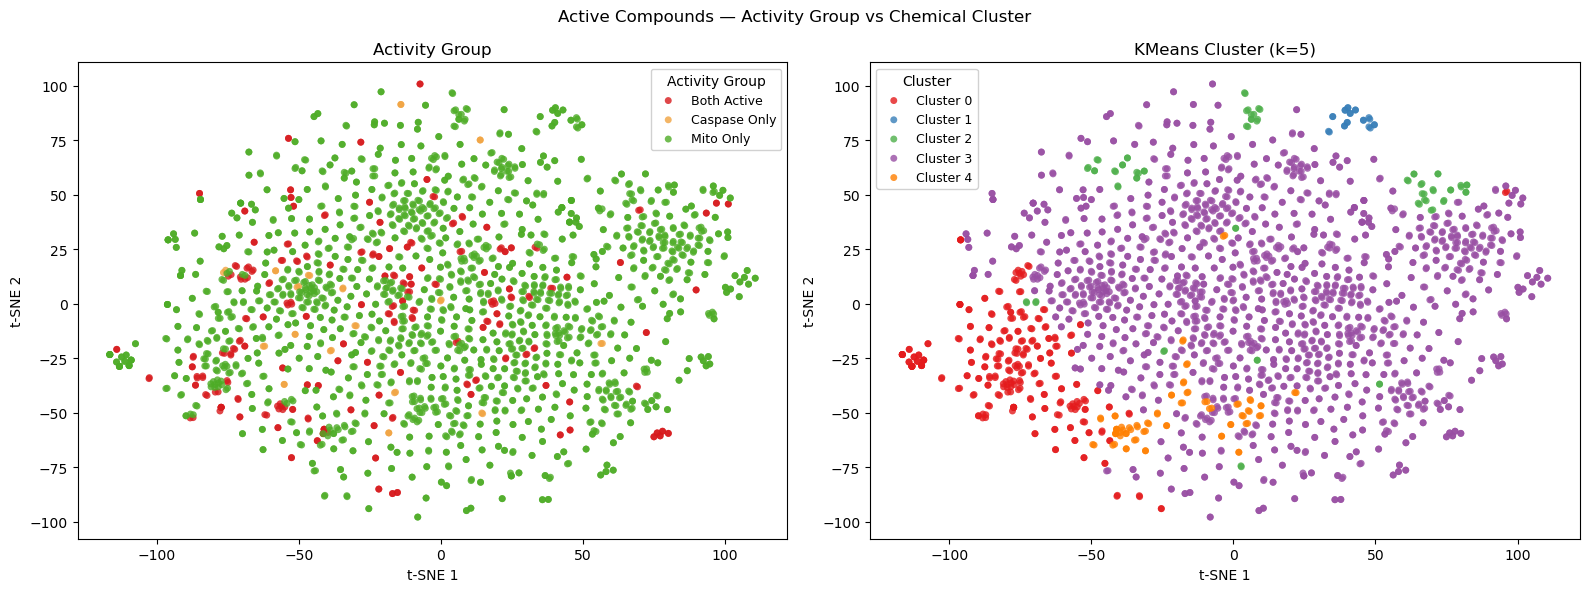

In [25]:
# ── Side-by-side t-SNE: activity group vs cluster ─────────────────────────────
# Left shows which activity group each compound belongs to.
# Right shows which cluster it was assigned to.
# Comparing both panels reveals whether clusters align with biology.

CLUSTER_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3','#ff7f00']
GROUP_COLORS   = {'Mito Only':'#4dac26','Caspase Only':'#f1a340','Both Active':'#d7191c'}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: colour by activity group
ax1 = axes[0]
for grp, gdf in valid.groupby('group'):
    ax1.scatter(gdf['tsne_x'], gdf['tsne_y'],
                c=GROUP_COLORS[grp], s=25, label=grp, alpha=0.8, edgecolors='none')
ax1.legend(title='Activity Group', framealpha=0.9, fontsize=9)
ax1.set_title('Activity Group'); ax1.set_xlabel('t-SNE 1'); ax1.set_ylabel('t-SNE 2')

# Right: colour by cluster
ax2 = axes[1]
for cid in sorted(valid['cluster'].unique()):
    gdf = valid[valid['cluster'] == cid]
    ax2.scatter(gdf['tsne_x'], gdf['tsne_y'],
                c=CLUSTER_COLORS[cid], s=25, label=f'Cluster {cid}',
                alpha=0.8, edgecolors='none')
ax2.legend(title='Cluster', framealpha=0.9, fontsize=9)
ax2.set_title('KMeans Cluster (k=5)'); ax2.set_xlabel('t-SNE 1'); ax2.set_ylabel('t-SNE 2')

plt.suptitle('Active Compounds — Activity Group vs Chemical Cluster', fontsize=12)
plt.tight_layout()
plt.show()

Cluster composition (counts):
group    Both Active  Caspase Only  Mito Only  Total  Both Active %
cluster                                                            
0                 64             6        202    272           23.5
1                  0             0         24     24            0.0
2                  2             0         74     76            2.6
3                210            26       1580   1816           11.6
4                 12             2         64     78           15.4


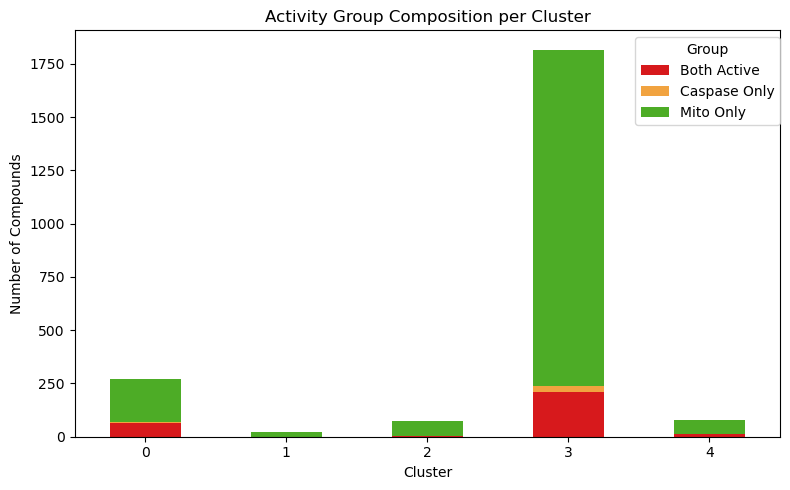

In [26]:
# ── Cluster composition: activity group breakdown per cluster ──────────────────
# Shows how many Both-Active, Caspase-Only and Mito-Only compounds
# fall in each cluster, and what % of each cluster is dual-active.
# A high Both-Active % in a cluster = that chemical family is particularly
# prone to activating both caspase and mitochondrial assays.

cross = pd.crosstab(valid['cluster'], valid['group'])

# Reorder columns for readability
col_order = [c for c in ['Both Active','Caspase Only','Mito Only'] if c in cross.columns]
cross = cross[col_order]
cross['Total'] = cross.sum(axis=1)
cross['Both Active %'] = (cross.get('Both Active', 0) / cross['Total'] * 100).round(1)

print('Cluster composition (counts):')
print(cross.to_string())

# Bar chart: stacked composition
cross[col_order].plot(
    kind='bar', stacked=True, figsize=(8, 5),
    color=['#d7191c','#f1a340','#4dac26']
)
plt.xlabel('Cluster'); plt.ylabel('Number of Compounds')
plt.title('Activity Group Composition per Cluster')
plt.xticks(rotation=0); plt.legend(title='Group', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

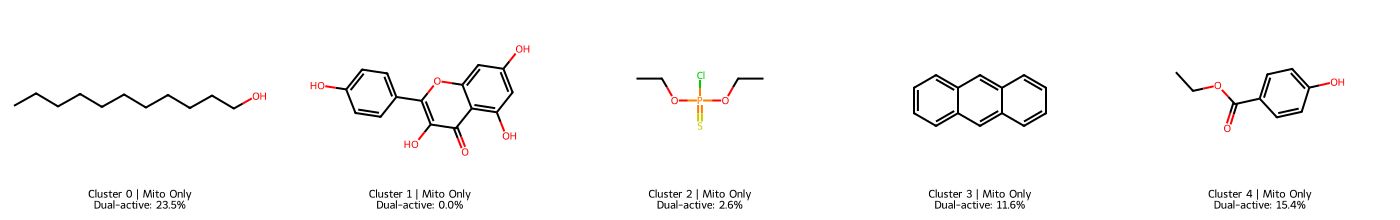

In [27]:
# ── Representative structures per cluster ─────────────────────────────────────
# For each cluster we pick the compound whose fingerprint is closest to the
# cluster centroid (most 'average' structure for that chemical family).
# Legend shows: cluster number, activity group, Both-Active % for that cluster.

from IPython.display import display, SVG

rep_mols, rep_legends = [], []

for cid in sorted(valid['cluster'].unique()):
    idx = valid[valid['cluster'] == cid].index.tolist()
    cluster_fps = fp_matrix[idx]                        # fingerprints in this cluster
    centroid    = cluster_fps.mean(axis=0)              # mean fingerprint = centroid

    # Pick the compound with smallest Euclidean distance to the centroid
    dists   = ((cluster_fps - centroid) ** 2).sum(axis=1)
    best_i  = idx[dists.argmin()]
    row     = valid.iloc[best_i]

    mol = Chem.MolFromSmiles(row[SMILES_COL])
    if mol:
        ba_pct = cross.loc[cid, 'Both Active %']
        rep_mols.append(mol)
        rep_legends.append(f"Cluster {cid} | {row['group']}\nDual-active: {ba_pct}%")

svg = Draw.MolsToGridImage(
    rep_mols,
    molsPerRow=5,
    subImgSize=(280, 220),
    legends=rep_legends,
    useSVG=True
)
svg

In [28]:
# ── Fragment Enrichment: Fisher's Exact Test (Both-Active vs Single-Active) ───
# Excluding inactives, we compare:
#   both-active  = activated BOTH caspase AND mito assays (dual mechanism)
#   single-active = activated only ONE assay (caspase-only or mito-only)
# Enriched fragments (OR>1, p<0.05) are structural features specific to
# dual-mechanism toxicity, not just general bioactivity.

def brics_set(smi):
    """Return the unique set of BRICS fragments for a SMILES string."""
    mol = Chem.MolFromSmiles(smi)
    return frozenset(BRICS.BRICSDecompose(mol)) if mol else frozenset()

# Fragment sets for both-active and single-active (caspase-only + mito-only)
both_sets   = [brics_set(s) for s in both_df[SMILES_COL]]
single_sets = [brics_set(s) for s in pd.concat([casp_df, mito_df])[SMILES_COL]]
all_frags   = set().union(*both_sets, *single_sets)
n_both, n_single = len(both_sets), len(single_sets)
print(f"Both-active: {n_both}  |  Single-active: {n_single}  |  Unique fragments: {len(all_frags)}")

# Run Fisher's test for every fragment
rows = []
for frag in all_frags:
    a = sum(1 for fs in both_sets   if frag in fs)   # both-active   WITH frag
    c = sum(1 for fs in single_sets if frag in fs)   # single-active WITH frag
    b, d = n_both - a, n_single - c                  # WITHOUT frag counts
    if a == 0:
        continue
    odds, pval = fisher_exact([[a, b], [c, d]], alternative="greater")
    rows.append({"fragment": frag, "odds_ratio": odds, "p_value": pval,
                 "n_both_active": a, "n_single_active": c})

enrich_df = pd.DataFrame(rows).sort_values("p_value")

# Keep only significant hits
alerts = enrich_df[(enrich_df["p_value"] < 0.05) & (enrich_df["odds_ratio"] > 1)].copy()
print(f"Significant enriched fragments: {len(alerts)}")
print(alerts[["fragment","odds_ratio","p_value","n_both_active","n_single_active"]].head(10).to_string(index=False))

Both-active: 288  |  Single-active: 1978  |  Unique fragments: 1172
Significant enriched fragments: 147
                                                              fragment  odds_ratio      p_value  n_both_active  n_single_active
[3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*])cccc1C3=O         inf 6.249403e-08              8                0
                                [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1         inf 6.249403e-08              8                0
                               [3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC         inf 4.026315e-06              6                0
                                              [16*]c1cc([16*])c(O)cc1C         inf 4.026315e-06              6                0
                                                      [8*]CCCCCCCCCCCC   21.021277 8.993407e-05              6                2
                                                      [4*]CCCCCCCCCCCC   21.021277 8.993407e-05              6                2


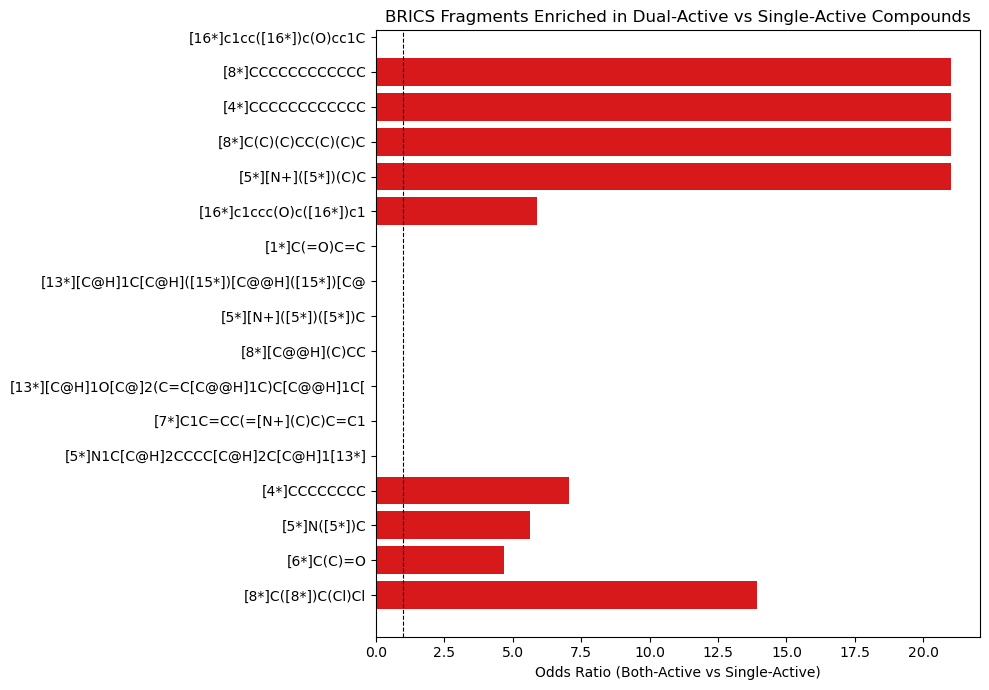

In [29]:
# ── Bar chart: top enriched structural alerts ─────────────────────────────────
top_n = min(20, len(alerts))
top   = alerts.head(top_n).copy()

# Red bars = OR >= 3 (strongly enriched in dual-active), orange = OR < 3
colors = ["#d7191c" if or_ >= 3 else "#fdae61" for or_ in top["odds_ratio"]]
labels = top["fragment"].str[:40].tolist()

plt.figure(figsize=(10, 7))
plt.barh(labels[::-1], top["odds_ratio"].values[::-1], color=colors[::-1])
plt.axvline(1, color="black", linestyle="--", linewidth=0.8)  # OR=1 baseline
plt.xlabel("Odds Ratio (Both-Active vs Single-Active)")
plt.title("BRICS Fragments Enriched in Dual-Active vs Single-Active Compounds")
plt.tight_layout()
plt.show()

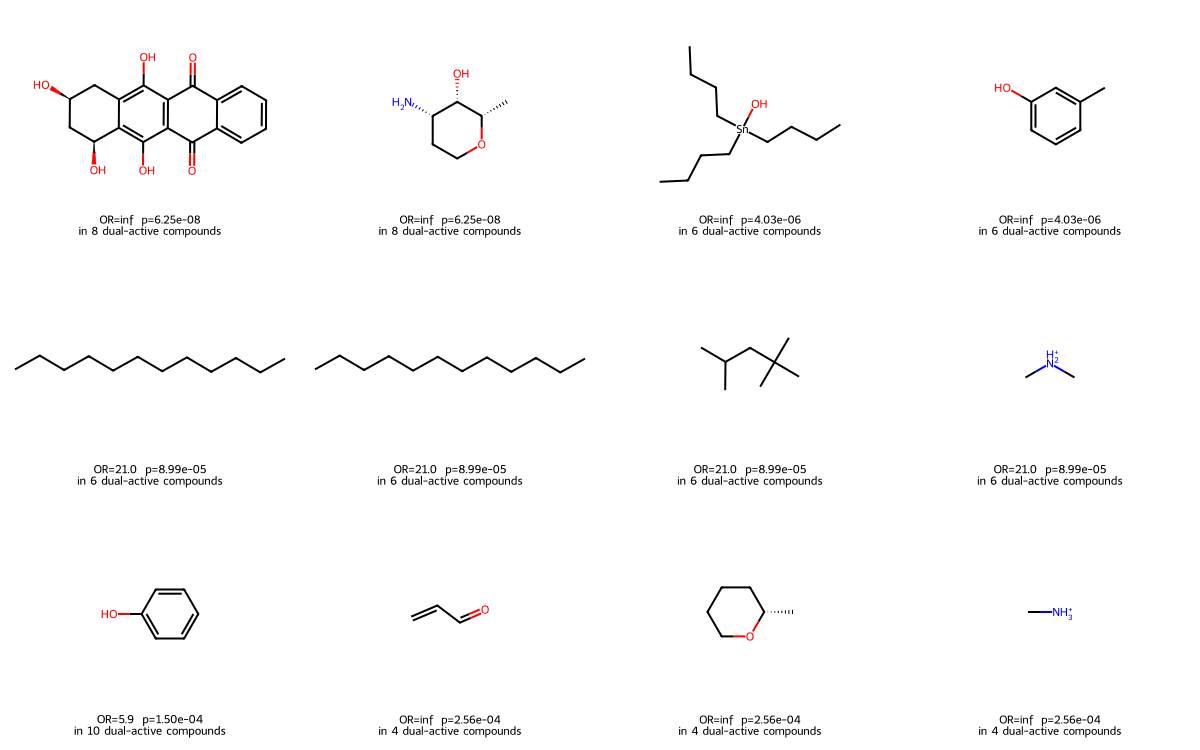

In [30]:
# ── Structure grid: top 12 enriched BRICS fragments ─────────────────────────
# These are the fragment *pieces* (substructures) whose presence is statistically
# enriched in Both-Active compounds vs Single-Active compounds (Fisher's test).
# They are NOT full toxic compounds — they are recurring motifs found inside them.
# A high OR means compounds containing this fragment are far more likely
# to activate both caspase AND mito assays than compounds lacking it.

from IPython.display import display, SVG

mols, legends = [], []
for _, row in alerts.head(12).iterrows():
    # Strip BRICS dummy atoms ([3*], [16*] etc.) so RDKit can parse the fragment
    clean = re.sub(r'\[\d+\*\]', '[H]', row['fragment'])
    mol = Chem.MolFromSmiles(clean)
    if mol:
        mols.append(mol)
        legends.append(
            f"OR={row['odds_ratio']:.1f}  p={row['p_value']:.2e}\n"
            f"in {row['n_both_active']} dual-active compounds"
        )

# useSVG=True avoids the Cairo 'no draw context' bug in RDKit 2025.09.x
svg = Draw.MolsToGridImage(
    mols, molsPerRow=4, subImgSize=(300, 250),
    legends=legends, useSVG=True
)
display(svg)

In [31]:
# ── Save individual fragment PNGs for LaTeX table ────────────────────────────
# Generates fragment_table14_a.png … fragment_table14_i.png in results/
# Uses a deterministic sort (p_value → odds_ratio desc → fragment SMILES)
# so the images always match the printed table below.

import string
from PIL import Image
import io, os

OUT_DIR = "/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/fragment_images"
os.makedirs(OUT_DIR, exist_ok=True)

# Deterministic ordering: primary sort p_value asc, secondary OR desc, tertiary SMILES
table_df = (
    alerts
    .sort_values(["p_value", "odds_ratio", "fragment"],
                 ascending=[True, False, True])
    .head(9)
    .reset_index(drop=True)
)

letters = list(string.ascii_lowercase)
saved = []

for idx, row in table_df.iterrows():
    clean = re.sub(r'\[\d+\*\]', '[H]', row['fragment'])
    mol = Chem.MolFromSmiles(clean)
    if mol is None:
        print(f"  [{letters[idx]}] Could not parse fragment — skipped")
        continue

    # Draw to PNG bytes (300×300 px)
    png_bytes = Draw.MolToImage(mol, size=(300, 300)).tobytes()
    img = Draw.MolToImage(mol, size=(300, 300))
    fname = f"fragment_table14_{letters[idx]}.png"
    fpath = os.path.join(OUT_DIR, fname)
    img.save(fpath)

    or_str = f"inf" if row['odds_ratio'] == float('inf') else f"{row['odds_ratio']:.2f}"
    saved.append({
        "label": letters[idx],
        "file": fname,
        "OR": or_str,
        "p_value": f"{row['p_value']:.3e}",
        "n_both": int(row['n_both_active']),
        "n_single": int(row['n_single_active']),
        "smiles": row['fragment']
    })
    print(f"  [{letters[idx]}] saved  OR={or_str}  p={row['p_value']:.3e}"
          f"  n_both={int(row['n_both_active'])}  n_single={int(row['n_single_active'])}"
          f"  {row['fragment'][:60]}")

print(f"\nSaved {len(saved)} fragment images to {OUT_DIR}")
print("\nLaTeX table rows (copy-paste):")
print()
for r in saved:
    or_tex = r"$\infty$" if r['OR'] == "inf" else r['OR']
    p_tex  = r['p_value'].replace("e-0", r"\times10^{-").replace("e-", r"\times10^{-") + ("}" if "times" in r['p_value'].replace("e-0", r"\times10^{-").replace("e-", r"\times10^{-") else "")
    print(f"fragment_{r['label']} & \\includegraphics[width=1.6cm,height=1.6cm,keepaspectratio]{{{r['file']}}} & {or_tex} & ${r['p_value']}$ & {r['n_both']} & {r['n_single']} \\\\[6pt]")


  [a] saved  OR=inf  p=6.249e-08  n_both=8  n_single=0  [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1
  [b] saved  OR=inf  p=6.249e-08  n_both=8  n_single=0  [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*]
  [c] saved  OR=inf  p=4.026e-06  n_both=6  n_single=0  [16*]c1cc([16*])c(O)cc1C
  [d] saved  OR=inf  p=4.026e-06  n_both=6  n_single=0  [3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC
  [e] saved  OR=21.02  p=8.993e-05  n_both=6  n_single=2  [4*]CCCCCCCCCCCC
  [f] saved  OR=21.02  p=8.993e-05  n_both=6  n_single=2  [5*][N+]([5*])(C)C
  [g] saved  OR=21.02  p=8.993e-05  n_both=6  n_single=2  [8*]C(C)(C)CC(C)(C)C
  [h] saved  OR=21.02  p=8.993e-05  n_both=6  n_single=2  [8*]CCCCCCCCCCCC
  [i] saved  OR=5.89  p=1.498e-04  n_both=10  n_single=12  [16*]c1ccc(O)c([16*])c1

Saved 9 fragment images to /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/fragment_images

LaTeX table rows (copy-paste):

fragment_a & \includegraphics[width=1.6cm,height=1.6cm,keepaspectratio]{fra

Ltr      OR       p-value  n_both  n_single  HeavyAtoms       PNG  Fragment SMILES
-------------------------------------------------------------------------------------------------------------------
  a     inf     6.249e-08       8         0           9    OK  [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1
  b     inf     6.249e-08       8         0          24    OK  [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*]
  c     inf     4.026e-06       6         0           8    OK  [16*]c1cc([16*])c(O)cc1C
  d     inf     4.026e-06       6         0          14    OK  [3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC
  e   21.02     8.993e-05       6         2          12    OK  [4*]CCCCCCCCCCCC
  f   21.02     8.993e-05       6         2           3    OK  [5*][N+]([5*])(C)C
  g   21.02     8.993e-05       6         2           8    OK  [8*]C(C)(C)CC(C)(C)C
  h   21.02     8.993e-05       6         2          12    OK  [8*]CCCCCCCCCCCC
  i    5.89     1.498e-04      10        12           7   

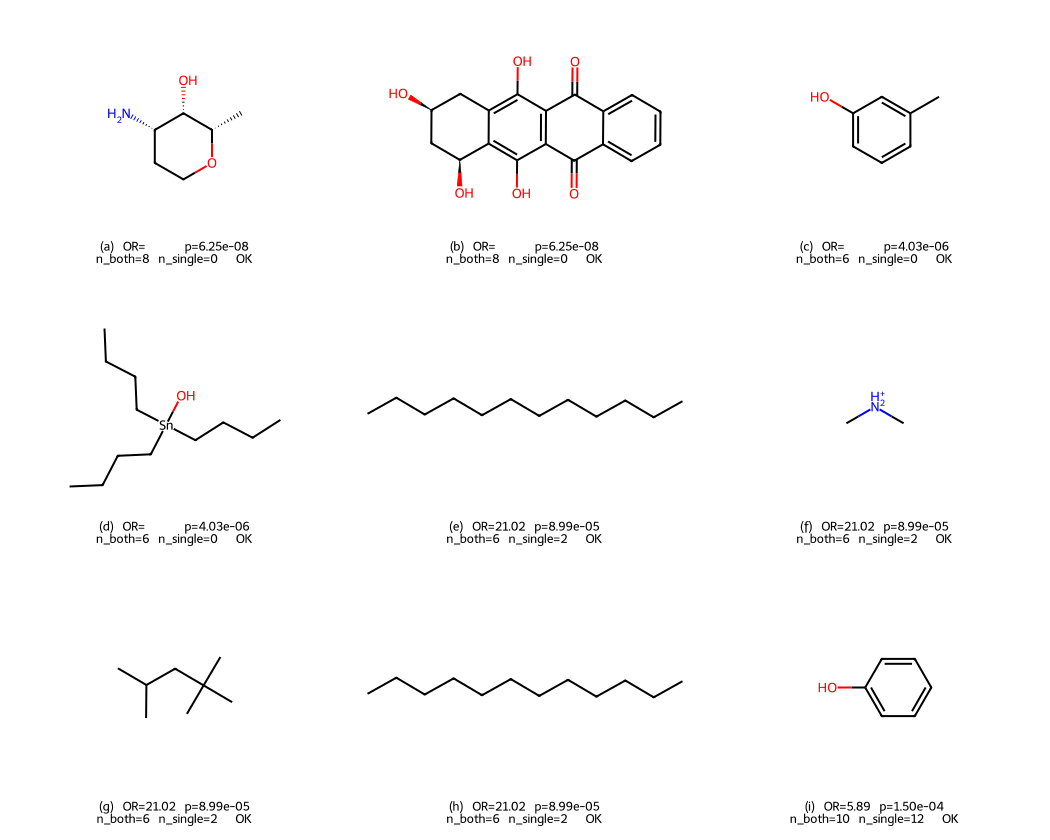

In [32]:
# ── Verify saved fragment structures for LaTeX table ─────────────────────────
# Displays each fragment (a–i) with its SMILES, OR, p-value, and atom count
# so you can confirm every structure looks correct before including it in the paper.
# Also checks that the PNG file was saved successfully (✓ / ✗ MISSING).

import string, os, re
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display, SVG

OUT_DIR = "/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/fragment_images"

# Same deterministic sort used in the save cell
table_df = (
    alerts
    .sort_values(["p_value", "odds_ratio", "fragment"], ascending=[True, False, True])
    .head(9)
    .reset_index(drop=True)
)

letters = list(string.ascii_lowercase)

# ── Text summary ──────────────────────────────────────────────────────────────
print(f"{'Ltr':>3}  {'OR':>6}  {'p-value':>12}  {'n_both':>6}  {'n_single':>8}  {'HeavyAtoms':>10}  {'PNG':>8}  Fragment SMILES")
print("-" * 115)

mols_verify, legends_verify = [], []

for idx, row in table_df.iterrows():
    ltr   = letters[idx]
    clean = re.sub(r'\[\d+\*\]', '[H]', row['fragment'])
    mol   = Chem.MolFromSmiles(clean)
    heavy = mol.GetNumHeavyAtoms() if mol else "ERR"
    or_str = "inf" if row['odds_ratio'] == float('inf') else f"{row['odds_ratio']:.2f}"
    fname  = f"fragment_table14_{ltr}.png"
    file_ok = "  OK" if os.path.exists(os.path.join(OUT_DIR, fname)) else "MISSING"

    print(f"  {ltr}  {or_str:>6}  {row['p_value']:>12.3e}"
          f"  {int(row['n_both_active']):>6}  {int(row['n_single_active']):>8}"
          f"  {str(heavy):>10}  {file_ok}  {row['fragment'][:60]}")

    if mol:
        mols_verify.append(mol)
        legends_verify.append(
            f"({ltr})  OR={'∞' if or_str=='inf' else or_str}  p={row['p_value']:.2e}\n"
            f"n_both={int(row['n_both_active'])}  n_single={int(row['n_single_active'])}  {file_ok}"
        )

# ── Structure grid ─────────────────────────────────────────────────────────────
print(f"\nShowing {len(mols_verify)} structures (a → i, left-to-right, top-to-bottom):\n")
svg = Draw.MolsToGridImage(
    mols_verify,
    molsPerRow=3,
    subImgSize=(350, 280),
    legends=legends_verify,
    useSVG=True
)
display(svg)

---
## Composite Toxicity Score
Combines **caspase breadth** (how many of the 13 cell-line assays a compound activated)
with a **mito bonus** (+3 if the compound is mito-active).

```
composite_score = caspase_breadth + 3 × mito_active
```

- `caspase_breadth` (0–13): counts how many caspase assay columns show 'Active'
- `mito_active` (0 or 1): 1 if compound is Both-Active or Mito-Only
- The ×3 weight makes mito activity as impactful as activating 3 caspase cell lines

Higher score = broader, dual-mechanism toxicity.

In [33]:
# ── Build composite toxicity score (active compounds only) ───────────────────
# Step 1: compute caspase breadth from the multi-cell-line comparison table.
# Each AID column stores 'Active', 'Inactive', or NaN for one caspase assay.
casp_all = pd.read_csv(
    "/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/"
    "all_cell_line_comparisions/compund_comparison_caspase_all.csv"
)
aid_cols = [c for c in casp_all.columns if c.startswith('AID')]
casp_all['caspase_breadth'] = (casp_all[aid_cols] == 'Active').sum(axis=1)

# Step 2: master table — active groups only, no inactives
active_cmpds = pd.concat([both_df, casp_df, mito_df], ignore_index=True)

# Step 3: merge caspase breadth
merged = active_cmpds.merge(
    casp_all[['PUBCHEM_CID', 'caspase_breadth']],
    on='PUBCHEM_CID', how='left'
)
merged['caspase_breadth'] = merged['caspase_breadth'].fillna(0).astype(int)

# Step 4: mito_active flag — 1 for Both-Active or Mito-Only, else 0
merged['mito_active'] = merged['group'].isin(['Both Active', 'Mito Only']).astype(int)

# Step 5: composite score
#   caspase_breadth = how many of 13 cell lines showed caspase activation
#   +3 bonus for mito activity (weighted equally to ~3 caspase cell lines)
merged['toxicity_score'] = merged['caspase_breadth'] + 3 * merged['mito_active']

print('Score distribution (active compounds only):')
print(merged['toxicity_score'].value_counts().sort_index())
print(f"\nMax score : {merged['toxicity_score'].max()}")
print(f"Mean score: {merged['toxicity_score'].mean():.2f}")

Score distribution (active compounds only):
toxicity_score
0       30
1        2
2        2
3     2060
4      132
5       10
6        8
7        4
8        6
9        4
10       2
11       2
12       4
Name: count, dtype: int64

Max score : 12
Mean score: 3.10


[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerator
[19:04:43] DEPRECATION WARNING: please use MorganGenerat

Running t-SNE on 2266 active compounds...
Done.


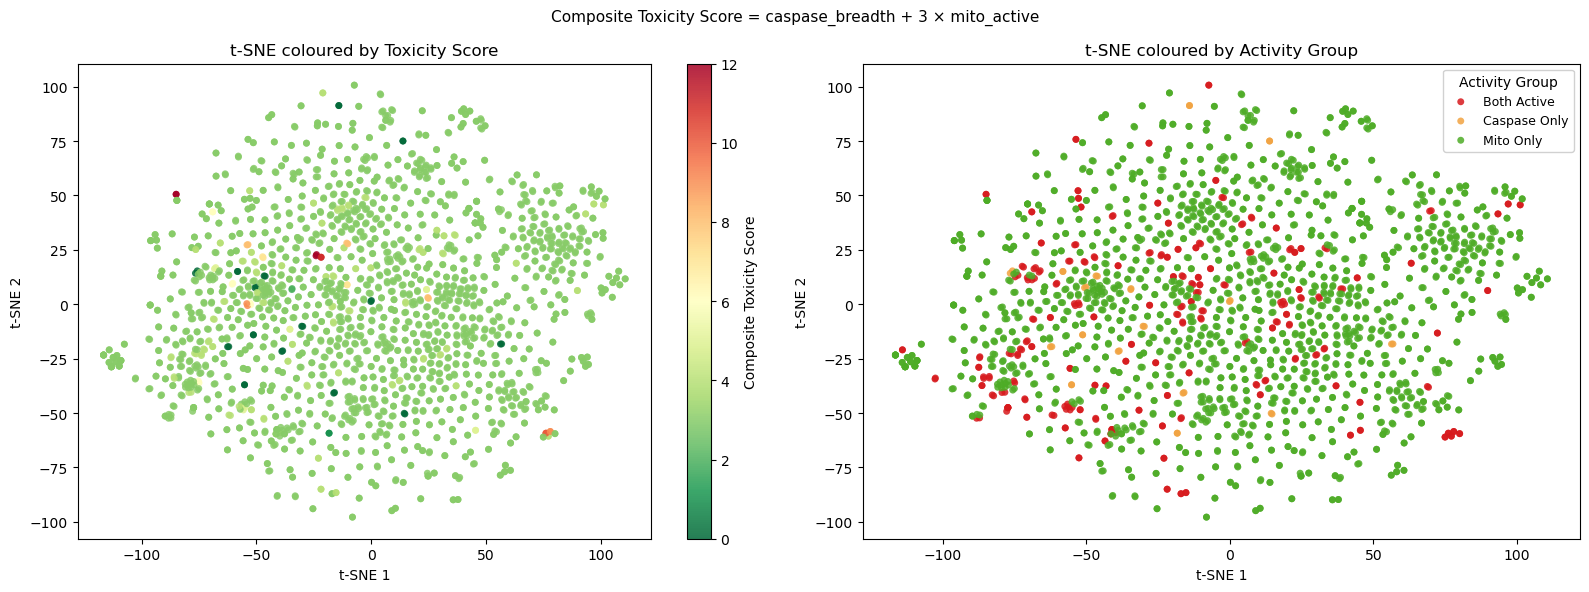


Top 10 most toxic compounds:
 PUBCHEM_CID       group  caspase_breadth  mito_active  toxicity_score
       11057 Both Active                9            1              12
     5288209 Both Active                9            1              12
       11057 Both Active                9            1              12
     5288209 Both Active                9            1              12
     2724411 Both Active                8            1              11
     2724411 Both Active                8            1              11
       62770 Both Active                7            1              10
       62770 Both Active                7            1              10
      108005 Both Active                6            1               9
      443939 Both Active                6            1               9


In [34]:
# ── t-SNE coloured by toxicity score (active compounds only) ─────────────────
# All compounds here have score >= 1 (at least one assay active).
# Clustering by score on this plot means structural similarity drives
# the extent of dual-mechanism toxicity, not just presence/absence.

merged['fp'] = merged[SMILES_COL].apply(smiles_to_fp)
plot_valid = merged[merged['fp'].notna()].copy().reset_index(drop=True)
fp_mat = np.array([list(fp) for fp in plot_valid['fp']])

print(f'Running t-SNE on {len(plot_valid)} active compounds...')
tsne2 = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
coords2 = tsne2.fit_transform(fp_mat)
plot_valid['tsne_x'], plot_valid['tsne_y'] = coords2[:, 0], coords2[:, 1]
print('Done.')

# ── Plot: left = gradient by score, right = activity group ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: continuous colour gradient
ax = axes[0]
sc = ax.scatter(plot_valid['tsne_x'], plot_valid['tsne_y'],
                c=plot_valid['toxicity_score'], cmap='RdYlGn_r',
                s=25, alpha=0.85, edgecolors='none')
plt.colorbar(sc, ax=ax, label='Composite Toxicity Score')
ax.set_title('t-SNE coloured by Toxicity Score')
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')

# Right: colour by activity group
GROUP_COLORS = {'Mito Only':'#4dac26', 'Caspase Only':'#f1a340', 'Both Active':'#d7191c'}
ax2 = axes[1]
for grp, gdf in plot_valid.groupby('group'):
    ax2.scatter(gdf['tsne_x'], gdf['tsne_y'],
                c=GROUP_COLORS[grp], s=25, label=grp, alpha=0.85, edgecolors='none')
ax2.legend(title='Activity Group', framealpha=0.9, fontsize=9)
ax2.set_title('t-SNE coloured by Activity Group')
ax2.set_xlabel('t-SNE 1'); ax2.set_ylabel('t-SNE 2')

plt.suptitle('Composite Toxicity Score = caspase_breadth + 3 × mito_active', fontsize=11)
plt.tight_layout()
plt.show()

# Top 10 most toxic compounds
print('\nTop 10 most toxic compounds:')
print(plot_valid.nlargest(10, 'toxicity_score')
      [['PUBCHEM_CID','group','caspase_breadth','mito_active','toxicity_score']].to_string(index=False))